# C4J manifold position experiment (Oct 2026)

Controlled follow-up for the HardwareX revision (OHX-D-26-00256). One 150 mL overnight culture of
C4J was split so that every prep starts from the same material:

- **By hand:** 3 preps, processed first.
- **Opentrons + vacuum manifold:** 3 runs x 24 ports (A1-D6), processed sequentially on the same
  day from the same lysate (run 1 -> run 2 -> run 3).

Because plasmid, strain and culture are fixed, yield differences can only come from the method,
the manifold port, or the processing order. Questions this notebook answers:

1. Does yield depend on manifold port? (R1)
2. Where does the Opentrons variability come from? (R7)
3. How do Opentrons and by-hand yields compare on matched material? (R5)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import arcadia_pycolor as apc
from scipy import stats
from pathlib import Path

color_opentrons = apc.palettes.primary[4]
color_byhand = apc.palettes.primary[2]
# Runs were processed in order 1 -> 3, so they are shaded dark -> light
run_colors = {'1': apc.palettes.purple_shades[0], '2': apc.palettes.purple_shades[2],
              '3': apc.palettes.purple_shades[3]}

PLOT_DIR = Path('../plots/c4j')
PLOT_DIR.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(0)


def fmt_p(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'


def style(ax):
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

In [2]:
raw = pd.read_csv('../data/C4JMiniprepYieldsOct2026.csv', encoding='utf-8-sig').set_index('Position')
raw.columns = raw.columns.astype(str)

hand = raw.loc['Hand'].astype(float)
ot = raw.drop(index='Hand').astype(float)  # 24 ports x 3 runs
RUNS = list(ot.columns)
PORTS = list(ot.index)

long = ot.reset_index().melt(id_vars='Position', var_name='Run', value_name='Yield')
long['Row'] = long['Position'].str[0]
long['Col'] = long['Position'].str[1:].astype(int)
long['Edge'] = long['Row'].isin(['A', 'D']) | long['Col'].isin([1, 6])
# Yield as % of its run's mean removes the run effect, so ports can be compared directly
long['Rel'] = 100 * long['Yield'] / long.groupby('Run')['Yield'].transform('mean')

print(f"By hand: {hand.values}")
print(f"Opentrons: {len(PORTS)} ports x {len(RUNS)} runs = {ot.size} preps")
ot

By hand: [68.8 67.6 78.6]
Opentrons: 24 ports x 3 runs = 72 preps


,1,2,3
Position,,,
A1,72.7,75.6,58.3
A2,72.5,67.9,63.2
A3,67.9,56.6,57.6
A4,78.6,61.1,42.1
A5,55.9,66.1,63.3
A6,81.2,71.5,69.9
B1,77.7,71.7,51.1
B2,70.3,68.4,49.5
B3,68.8,57.7,52.6


## 1. Descriptive statistics

CV = SD / mean x 100 (sample SD, ddof=1), the same definition as `miniprep.ipynb`. Geometric CV
= sqrt(exp(s^2) - 1) x 100 where s is the SD of log yield. 95% CIs are percentile bootstraps
(10,000 resamples), reported only for n >= 5; the by-hand group (n = 3) is too small for a CI.

In [3]:
def cv(x):
    return 100 * np.std(x, ddof=1) / np.mean(x)


def geo_cv(x):
    s = np.std(np.log(x), ddof=1)
    return 100 * np.sqrt(np.exp(s ** 2) - 1)


def boot_ci(x, fn, n_boot=10000):
    x = np.asarray(x)
    samples = x[rng.integers(0, len(x), (n_boot, len(x)))]
    return np.percentile([fn(s) for s in samples], [2.5, 97.5])


groups = {'By hand': hand.values,
          **{f'OT run {r}': ot[r].values for r in RUNS},
          'OT pooled': ot.values.ravel()}

summary = []
for name, x in groups.items():
    # Resampling 3 values gives a degenerate bootstrap, so CIs are only reported for n >= 5
    if len(x) >= 5:
        mean_ci = '{:.1f}-{:.1f}'.format(*boot_ci(x, np.mean))
        cv_ci = '{:.1f}-{:.1f}'.format(*boot_ci(x, cv))
    else:
        mean_ci = cv_ci = 'n/a'
    summary.append({'Group': name, 'n': len(x), 'Mean': x.mean(), 'Mean 95% CI': mean_ci,
                    'SD': np.std(x, ddof=1), 'Min': x.min(), 'Max': x.max(),
                    'CV (%)': cv(x), 'CV 95% CI': cv_ci, 'Geometric CV (%)': geo_cv(x)})
summary_df = pd.DataFrame(summary).set_index('Group')

within_run_cv = np.mean([cv(ot[r]) for r in RUNS])
print(f"Mean within-run Opentrons CV: {within_run_cv:.1f}% (pooled CV also includes the run-to-run shift)")
summary_df.round(1)

Mean within-run Opentrons CV: 16.3% (pooled CV also includes the run-to-run shift)


,n,Mean,Mean 95% CI,SD,Min,Max,CV (%),CV 95% CI,Geometric CV (%)
Group,,,,,,,,,
By hand,3,71.7,n/a,6.0,67.6,78.6,8.4,n/a,8.3
OT run 1,24,71.9,68.4-75.5,9.1,55.9,88.4,12.7,9.4-15.0,12.8
OT run 2,24,61.2,58.1-64.2,7.7,43.4,75.6,12.6,8.8-15.8,13.1
OT run 3,24,54.5,49.3-59.5,12.8,25.0,87.1,23.5,13.5-31.7,27.1
OT pooled,72,62.5,59.7-65.3,12.3,25.0,88.4,19.7,15.6-23.8,22.4


## 2. Opentrons vs by hand, and the effect of processing order

The hand preps were done first, then runs 1-3 in sequence, so processing order is a proxy for
how long the lysate waited before purification.

Each run is compared with the hand preps by Welch's t-test. For a single overall comparison the
three run means are used as the Opentrons observations, because preps within a run are not
independent of each other.

In [4]:
comparisons = []
for r in RUNS:
    welch = stats.ttest_ind(ot[r], hand, equal_var=False)
    comparisons.append({'Comparison': f'OT run {r} vs hand', 'OT mean': ot[r].mean(), 'Hand mean': hand.mean(),
                        'OT as % of hand': 100 * ot[r].mean() / hand.mean(), 'Welch p': welch.pvalue})
# Overall comparison: the 72 Opentrons preps are clustered by run (run explains ~40% of the
# variance), so they are not 72 independent observations. Each run is collapsed to its mean and the
# 3 run means are compared with the 3 hand preps by Welch's t-test, so the run is the unit of
# replication. This tests mean yield, consistent with the per-run comparisons above.
run_means = ot.mean(axis=0).values
overall = stats.ttest_ind(run_means, hand, equal_var=False)
comparisons.append({'Comparison': 'OT run means (n=3) vs hand', 'OT mean': run_means.mean(),
                    'Hand mean': hand.mean(), 'OT as % of hand': 100 * run_means.mean() / hand.mean(),
                    'Welch p': overall.pvalue})
comparison_df = pd.DataFrame(comparisons).set_index('Comparison')

# Linear trend in yield across the three Opentrons runs (run index 1, 2, 3)
trend = stats.linregress(long['Run'].astype(int), long['Yield'])
print(f"Opentrons trend across runs: {trend.slope:.1f} ng/uL per run "
      f"({100 * trend.slope / ot['1'].mean():.1f}% of run 1 per run), {fmt_p(trend.pvalue)}")
comparison_df.round(3)

Opentrons trend across runs: -8.7 ng/uL per run (-12.1% of run 1 per run), p < 0.001


,OT mean,Hand mean,OT as % of hand,Welch p
Comparison,,,,
OT run 1 vs hand,71.896,71.667,100.320,0.957
OT run 2 vs hand,61.204,71.667,85.401,0.075
OT run 3 vs hand,54.483,71.667,76.023,0.012
OT run means (n=3) vs hand,62.528,71.667,87.248,0.220


## 3. Does manifold port affect yield?

Additive two-way ANOVA without replication (port x run, one prep per port per run), written out
with numpy/scipy. Followed by a Friedman test (non-parametric, runs as blocks) and contrasts on
run-normalised yield for manifold row, column, and edge vs centre ports.

In [5]:
def two_way_anova(table):
    # Additive two-way ANOVA without replication: rows = ports, columns = runs
    Y = table.values
    grand = Y.mean()
    n_port, n_run = Y.shape
    ss_port = n_run * ((Y.mean(axis=1) - grand) ** 2).sum()
    ss_run = n_port * ((Y.mean(axis=0) - grand) ** 2).sum()
    ss_res = ((Y - grand) ** 2).sum() - ss_port - ss_run
    dfs = {'Port': n_port - 1, 'Run': n_run - 1, 'Residual': (n_port - 1) * (n_run - 1)}
    ss = {'Port': ss_port, 'Run': ss_run, 'Residual': ss_res}
    out = pd.DataFrame({'SS': ss, 'df': dfs})
    out['MS'] = out['SS'] / out['df']
    out['F'] = out['MS'] / out.loc['Residual', 'MS']
    out['p'] = [stats.f.sf(out.loc[k, 'F'], out.loc[k, 'df'], dfs['Residual']) for k in ('Port', 'Run')] + [np.nan]
    out.loc['Residual', 'F'] = np.nan
    return out


anova = two_way_anova(ot)
friedman = stats.friedmanchisquare(*[ot.loc[p].values for p in PORTS])
row_test = stats.f_oneway(*[g['Rel'].values for _, g in long.groupby('Row')])
col_test = stats.f_oneway(*[g['Rel'].values for _, g in long.groupby('Col')])
edge_test = stats.ttest_ind(long.loc[long['Edge'], 'Rel'], long.loc[~long['Edge'], 'Rel'], equal_var=False)

print(anova.round(3), '\n')
print(f"Friedman (port, runs as blocks): chi2 = {friedman.statistic:.1f}, {fmt_p(friedman.pvalue)}")
print(f"Manifold row (A-D), run-normalised: F = {row_test.statistic:.2f}, {fmt_p(row_test.pvalue)}")
print(f"Manifold column (1-6), run-normalised: F = {col_test.statistic:.2f}, {fmt_p(col_test.pvalue)}")
print(f"Edge ({long['Edge'].sum() // len(RUNS)} ports) vs centre ({(~long['Edge']).sum() // len(RUNS)} ports): "
      f"{long.loc[long['Edge'], 'Rel'].mean():.1f}% vs {long.loc[~long['Edge'], 'Rel'].mean():.1f}% of run mean, "
      f"{fmt_p(edge_test.pvalue)}")

spearman = {f'{a} vs {b}': stats.spearmanr(ot[a], ot[b]) for i, a in enumerate(RUNS) for b in RUNS[i + 1:]}
for k, v in spearman.items():
    print(f"Port rank agreement, run {k}: Spearman rho = {v.statistic:.2f}, {fmt_p(v.pvalue)}")

                SS  df        MS       F      p
Port      2304.038  23   100.176   0.971  0.516
Run       3701.412   2  1850.706  17.947  0.000
Residual  4743.455  46   103.119     NaN    NaN 

Friedman (port, runs as blocks): chi2 = 23.6, p = 0.428
Manifold row (A-D), run-normalised: F = 1.04, p = 0.379
Manifold column (1-6), run-normalised: F = 1.01, p = 0.420
Edge (16 ports) vs centre (8 ports): 99.7% vs 100.6% of run mean, p = 0.816
Port rank agreement, run 1 vs 2: Spearman rho = 0.17, p = 0.414
Port rank agreement, run 1 vs 3: Spearman rho = -0.11, p = 0.612
Port rank agreement, run 2 vs 3: Spearman rho = -0.03, p = 0.896


### Is any single port consistently low?

D6 sat below its run mean in all three runs. Picking out the worst of 24 ports after the fact is
a multiple-comparison problem, so the test is a permutation: shuffle ports within each run and ask
how often the *lowest* port mean is at least as low as the one observed.

In [6]:
port_rel = long.pivot(index='Position', columns='Run', values='Rel')
port_mean_rel = port_rel.mean(axis=1).sort_values()
below_mean = (port_rel < 100).sum(axis=1)

R = port_rel.values
perm_min = np.array([np.column_stack([rng.permutation(R[:, j]) for j in range(R.shape[1])]).mean(axis=1).min()
                     for _ in range(10000)])
lowest_port = port_mean_rel.index[0]
p_lowest = (perm_min <= port_mean_rel.iloc[0]).mean()
# Chance that at least one of 24 ports falls below the run mean in all 3 runs, if ports are exchangeable
p_any_always_below = 1 - (1 - 0.5 ** len(RUNS)) ** len(PORTS)

print(f"Lowest port: {lowest_port}, mean {port_mean_rel.iloc[0]:.1f}% of run mean "
      f"(runs: {', '.join(f'{v:.0f}%' for v in port_rel.loc[lowest_port])})")
print(f"Permutation p for the lowest port being this low by chance: {p_lowest:.3f}")
print(f"Ports below run mean in all {len(RUNS)} runs: {list(below_mean[below_mean == len(RUNS)].index)} "
      f"(expected by chance in at least one port: {100 * p_any_always_below:.0f}%)")
port_mean_rel.round(1).to_frame('Mean % of run mean').T

Lowest port: D6, mean 74.5% of run mean (runs: 84%, 88%, 51%)
Permutation p for the lowest port being this low by chance: 0.153
Ports below run mean in all 3 runs: ['B3', 'B6', 'D6'] (expected by chance in at least one port: 96%)


Position,D6,C6,C4,D4,C3,B6,A4,B3,C1,A3,...,C2,A5,B4,B1,D3,A2,D5,A1,C5,A6
Mean % of run mean,74.5,80.2,94.3,94.5,94.8,95.1,95.5,95.5,96.6,97.5,...,100.5,100.6,106.0,106.3,106.9,109.3,110.2,110.5,112.8,119.4


## 4. Where does the variability come from?

Variance components from the ANOVA mean squares: run = (MS_run - MS_res) / n_ports,
port = (MS_port - MS_res) / n_runs (floored at 0), residual = MS_res (prep-to-prep noise).

In [7]:
ms = anova['MS']
var_components = pd.Series({
    'Run (processing order)': max(0, (ms['Run'] - ms['Residual']) / len(PORTS)),
    'Port': max(0, (ms['Port'] - ms['Residual']) / len(RUNS)),
    'Residual (prep-to-prep)': ms['Residual'],
})
var_share = 100 * var_components / var_components.sum()
pd.DataFrame({'Variance': var_components, 'Share (%)': var_share, 'SD (ng/uL)': np.sqrt(var_components)}).round(1)

,Variance,Share (%),SD (ng/uL)
Run (processing order),72.8,41.4,8.5
Port,0.0,0.0,0.0
Residual (prep-to-prep),103.1,58.6,10.2


## 5. Sensitivity: run 3 without its two low outliers

Run 3 has the highest CV, driven by C6 (25 ng/uL) and D6 (28 ng/uL). Repeat the key numbers with
those two ports dropped from every run so the ANOVA stays balanced.

In [8]:
OUTLIER_PORTS = ['C6', 'D6']
ot_trim = ot.drop(index=OUTLIER_PORTS)
anova_trim = two_way_anova(ot_trim)

print(f"Run 3 CV: {cv(ot['3']):.1f}% with all ports, {cv(ot_trim['3']):.1f}% without {OUTLIER_PORTS}")
print(f"Mean within-run CV: {within_run_cv:.1f}% -> {np.mean([cv(ot_trim[r]) for r in RUNS]):.1f}%")
print(f"Port effect without {OUTLIER_PORTS}: F = {anova_trim.loc['Port', 'F']:.2f}, {fmt_p(anova_trim.loc['Port', 'p'])}")
print(f"Run effect without {OUTLIER_PORTS}: F = {anova_trim.loc['Run', 'F']:.2f}, {fmt_p(anova_trim.loc['Run', 'p'])}")

Run 3 CV: 23.5% with all ports, 17.4% without ['C6', 'D6']
Mean within-run CV: 16.3% -> 14.3%
Port effect without ['C6', 'D6']: F = 0.59, p = 0.900
Run effect without ['C6', 'D6']: F = 14.52, p < 0.001


## Figures

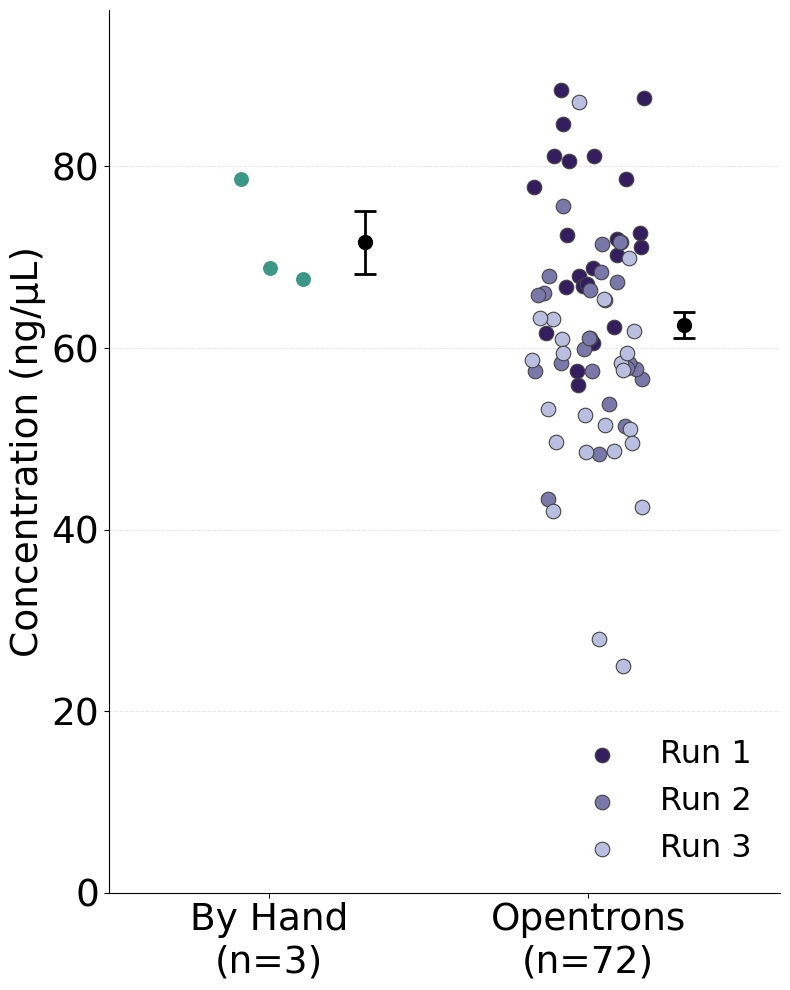

In [9]:
# A. Yield by method: every prep, coloured by run, with mean +/- SEM.
# Each panel is a function drawing onto an axis, so the standalone SVG and the combined figure
# share one implementation; each seeds its own jitter so points land in the same place in both.
def plot_yield_by_method(ax):
    jit = np.random.default_rng(1)
    ax.scatter(jit.uniform(-0.12, 0.12, len(hand)), hand, s=150, color=color_byhand,
               edgecolor='white', linewidth=1.5, zorder=3)
    for r in RUNS:
        ax.scatter(1 + jit.uniform(-0.18, 0.18, len(PORTS)), ot[r], s=110, color=run_colors[r],
                   edgecolor='#444444', linewidth=0.8, zorder=3, label=f'Run {r}')
    for x, vals in [(0, hand.values), (1, ot.values.ravel())]:
        ax.errorbar(x + 0.3, vals.mean(), yerr=stats.sem(vals), fmt='o', color='black',
                    markersize=10, capsize=8, elinewidth=2, capthick=2, zorder=4)

    ax.set_xticks([0, 1])
    ax.set_xticklabels([f'By Hand\n(n={len(hand)})', f'Opentrons\n(n={ot.size})'], fontsize=27)
    ax.set_ylabel('Concentration (ng/μL)', fontsize=27)
    ax.tick_params(axis='y', labelsize=27)
    ax.set_xlim(-0.5, 1.6)
    ax.set_ylim(0, max(hand.max(), ot.values.max()) * 1.1)
    ax.legend(fontsize=23, frameon=False, loc='lower right')
    style(ax)


fig, ax = plt.subplots(figsize=(8, 10))
plot_yield_by_method(ax)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'C4J_YieldByMethod.svg', dpi=1000, bbox_inches='tight')
plt.show()

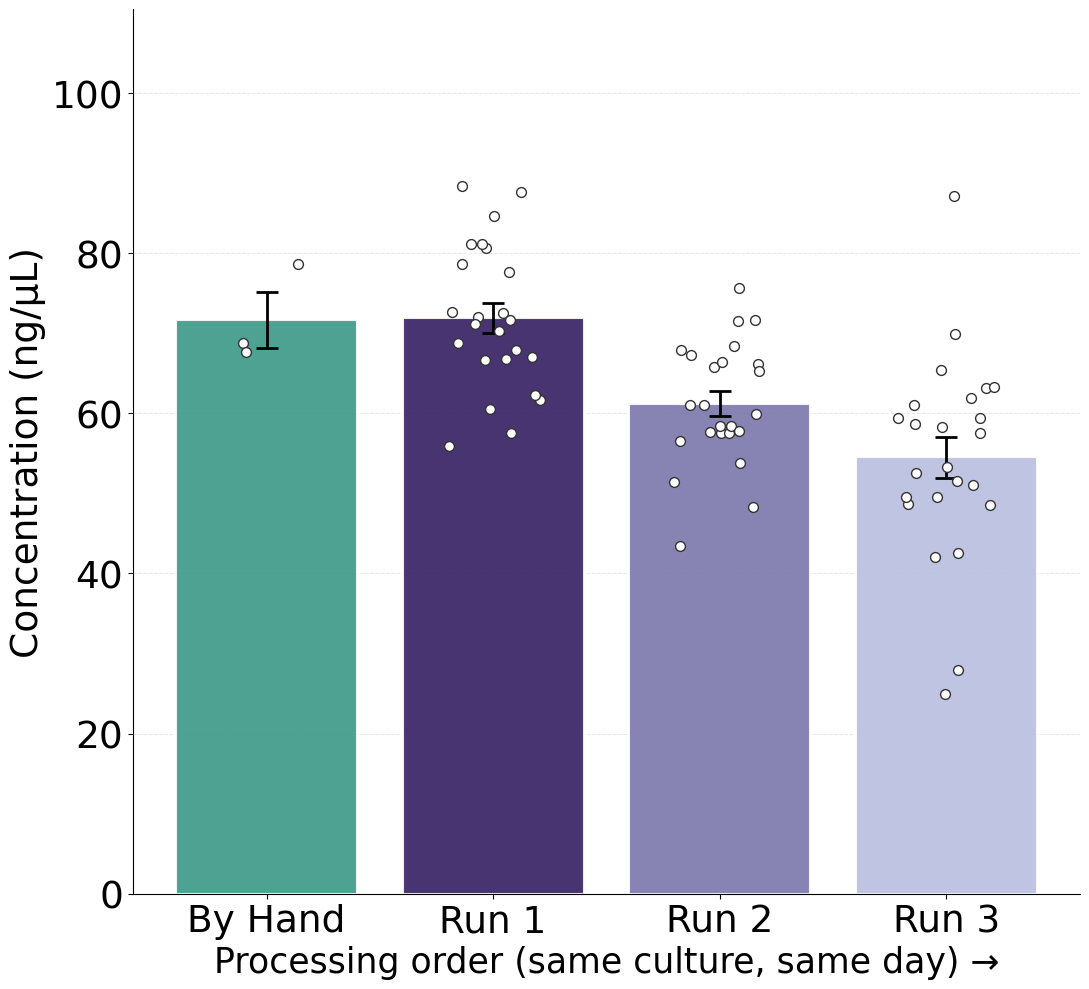

Legend stats:
  Run 1 vs hand: Welch p = 0.957
  Run 2 vs hand: Welch p = 0.075
  Run 3 vs hand: Welch p = 0.012
  Trend across runs: -8.7 ng/μL per run, p < 0.001


In [10]:
# B. Yield in processing order (hand first, then runs 1-3): mean +/- SEM, with CV and n per group
def plot_processing_order(ax):
    jit = np.random.default_rng(2)
    order = [('By Hand', hand.values, color_byhand)] + [(f'Run {r}', ot[r].values, run_colors[r]) for r in RUNS]
    for i, (label, vals, color) in enumerate(order):
        ax.bar(i, vals.mean(), yerr=stats.sem(vals), color=color, alpha=0.9, edgecolor='white',
               linewidth=1.5, capsize=8, error_kw={'linewidth': 2, 'elinewidth': 2, 'capthick': 2}, zorder=2)
        ax.scatter(i + jit.uniform(-0.22, 0.22, len(vals)), vals, s=50, color='white',
                   edgecolor='#333333', linewidth=1, zorder=3)
        # ax.text(i, vals.max() + 4, f'CV {cv(vals):.0f}%\nn={len(vals)}', ha='center', va='bottom', fontsize=21)

    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([o[0] for o in order], fontsize=27)
    ax.set_xlabel('Processing order (same culture, same day) →', fontsize=25)
    ax.set_ylabel('Concentration (ng/μL)', fontsize=27)
    ax.tick_params(axis='y', labelsize=27)
    ax.set_ylim(0, max(hand.max(), ot.values.max()) * 1.25)
    style(ax)


fig, ax = plt.subplots(figsize=(11, 10))
plot_processing_order(ax)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'C4J_ProcessingOrder.svg', dpi=1000, bbox_inches='tight')
plt.show()

print("Legend stats:")
for r in RUNS:
    print(f"  Run {r} vs hand: Welch {fmt_p(comparison_df.loc[f'OT run {r} vs hand', 'Welch p'])}")
print(f"  Trend across runs: {trend.slope:.1f} ng/μL per run, {fmt_p(trend.pvalue)}")

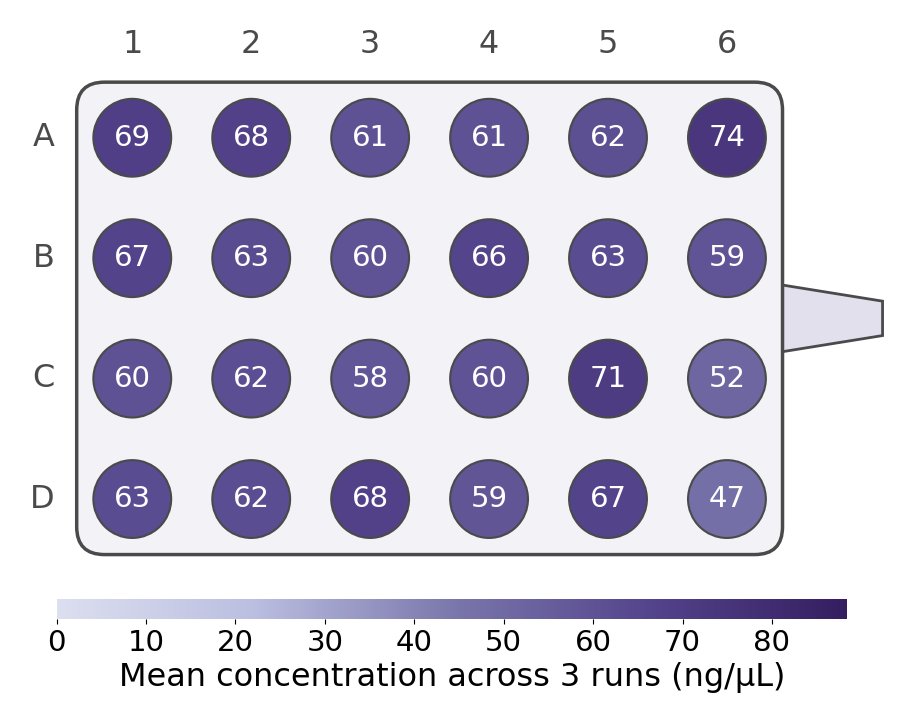

In [11]:
# C. Manifold map: mean yield per port, drawn on the manifold outline (darker = higher).
# Geometry is taken from the labware definition (jdvacuum_24_tuberack_500ul.json) and the
# technical drawing in Fig 1: 127 x 85 mm body, ports at x = 10-117 mm, y = 10-75 mm (row A at
# the back), and the vacuum cone fitting (18 mm long, 12.31 -> 6.19 mm) on the column-6 side.
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Circle, FancyBboxPatch, Polygon

BODY_W, BODY_H = 127, 85
CONE_LEN, CONE_BASE, CONE_TIP = 18, 12.31, 6.19
PORT_RADIUS = 7  # drawn larger than the 8 mm column seat so each port can hold its value
ROWS = sorted(long['Row'].unique())
COLS = sorted(long['Col'].unique())
port_x = dict(zip(COLS, np.linspace(10, 117, len(COLS))))
port_y = dict(zip(ROWS, np.linspace(75, 9.99, len(ROWS))))

# Purple scale built from the arcadia purple shades used for the Opentrons runs
purple_cmap = LinearSegmentedColormap.from_list(
    'ot_purples', [apc.palettes.purple_shades[i] for i in (4, 3, 2, 1, 0)])


def draw_manifold(ax, values, vmin, vmax, fontsize=21):
    norm = Normalize(vmin=vmin, vmax=vmax)
    body = '#F3F2F7'
    outline = '#4A4A4A'

    # Cone fitting first so the body overlaps its base
    mid = BODY_H / 2
    ax.add_patch(Polygon([(BODY_W - 1, mid - CONE_BASE / 2), (BODY_W + CONE_LEN, mid - CONE_TIP / 2),
                          (BODY_W + CONE_LEN, mid + CONE_TIP / 2), (BODY_W - 1, mid + CONE_BASE / 2)],
                         closed=True, facecolor='#E2E0EC', edgecolor=outline, linewidth=2, zorder=1))
    ax.add_patch(FancyBboxPatch((0, 0), BODY_W, BODY_H, boxstyle='round,pad=0,rounding_size=5',
                                facecolor=body, edgecolor=outline, linewidth=2.5, zorder=2))

    for r in ROWS:
        for c in COLS:
            v = values[f'{r}{c}']
            ax.add_patch(Circle((port_x[c], port_y[r]), PORT_RADIUS, facecolor=purple_cmap(norm(v)),
                                edgecolor=outline, linewidth=1.5, zorder=3))
            ax.text(port_x[c], port_y[r], f'{v:.0f}', ha='center', va='center', fontsize=fontsize,
                    color='white' if norm(v) > 0.5 else 'black', zorder=4)

    # Row and column labels outside the body, as on the labware
    for r in ROWS:
        ax.text(-4, port_y[r], r, ha='right', va='center', fontsize=fontsize + 2, color=outline)
    for c in COLS:
        ax.text(port_x[c], BODY_H + 4, str(c), ha='center', va='bottom', fontsize=fontsize + 2, color=outline)

    ax.set_xlim(-12, BODY_W + CONE_LEN + 2)
    ax.set_ylim(-3, BODY_H + 13)
    ax.set_aspect('equal')
    ax.axis('off')
    return plt.cm.ScalarMappable(norm=norm, cmap=purple_cmap)


port_mean = ot.mean(axis=1)


def plot_manifold_map(ax):
    sm = draw_manifold(ax, port_mean, vmin=0, vmax=ot.values.max())
    cbar = plt.colorbar(sm, ax=ax, orientation='horizontal', pad=0.04, aspect=40, shrink=0.85)
    cbar.set_label('Mean concentration across 3 runs (ng/μL)', fontsize=23)
    cbar.ax.tick_params(labelsize=21)
    cbar.outline.set_visible(False)


fig, ax = plt.subplots(figsize=(12, 9))
plot_manifold_map(ax)
plt.savefig(PLOT_DIR / 'C4J_ManifoldMap.svg', dpi=1000, bbox_inches='tight')
plt.show()

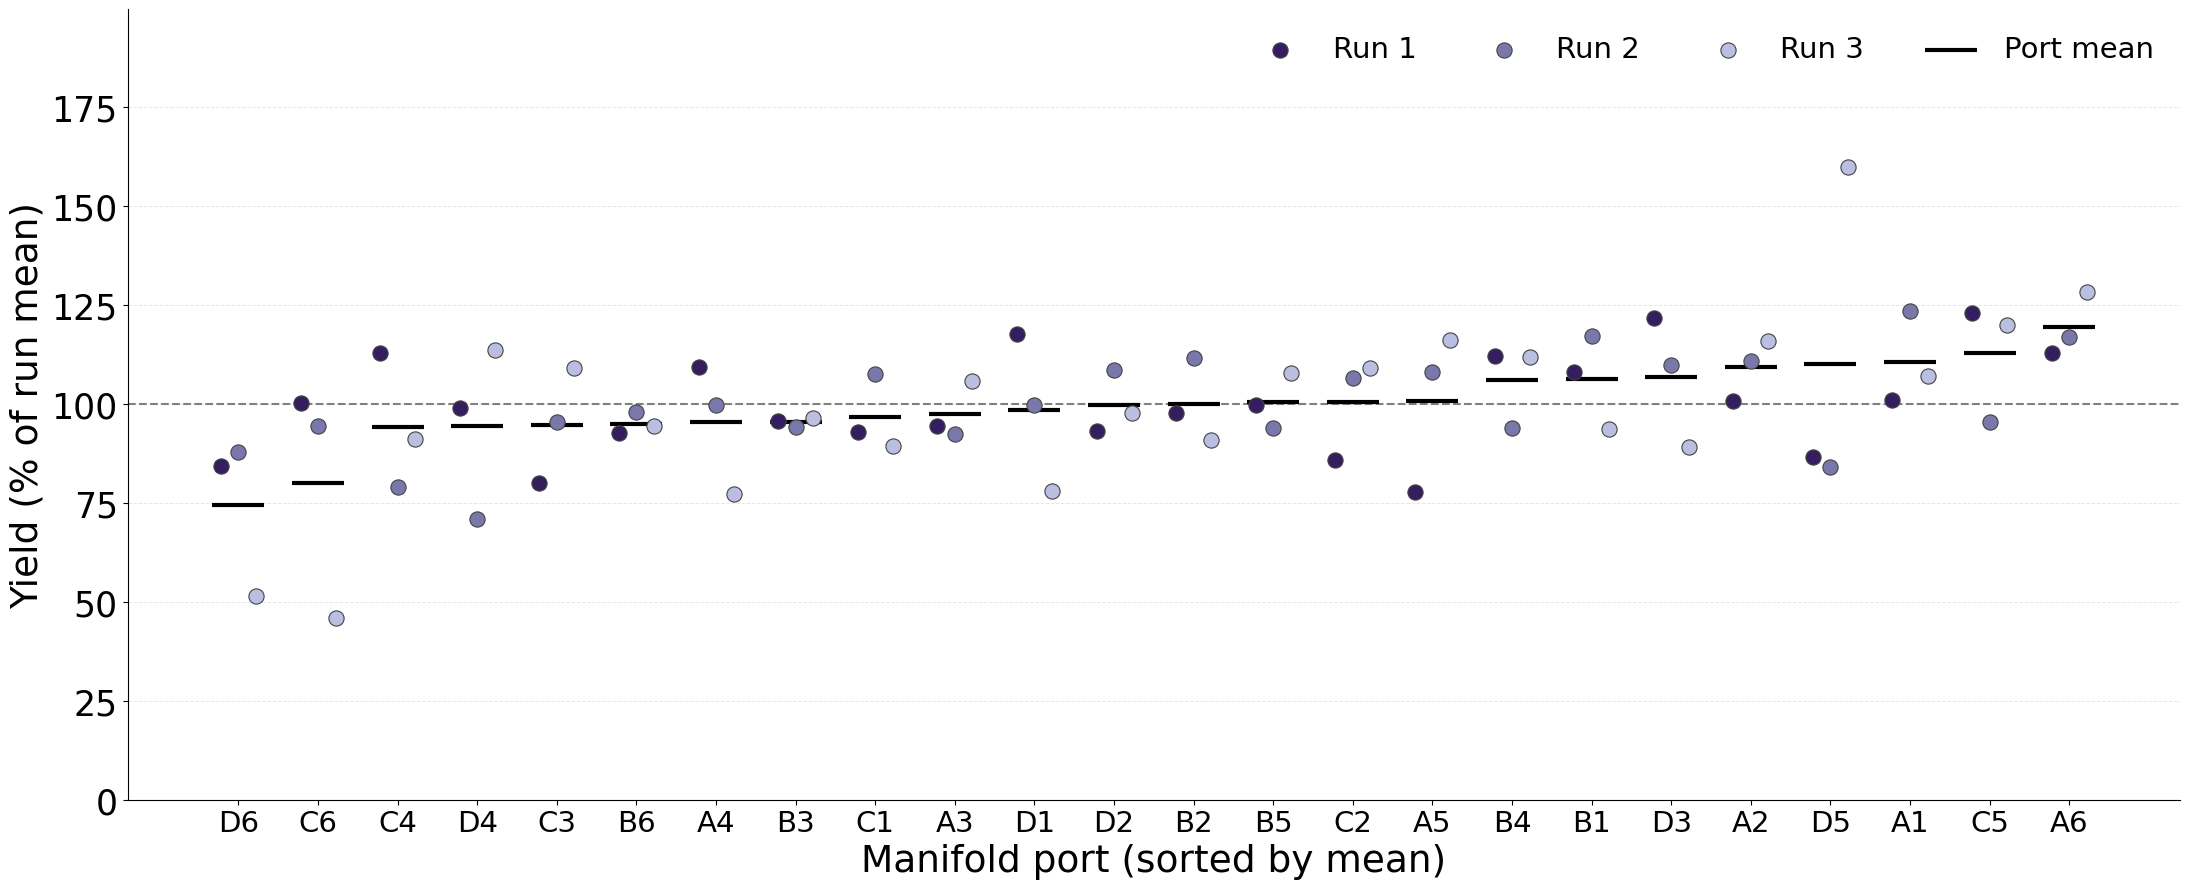

In [12]:
# D. Port consistency: run-normalised yield per port, ports sorted by mean
def plot_port_consistency(ax):
    sorted_ports = port_mean_rel.index
    x = np.arange(len(sorted_ports))
    # Runs are offset sideways so no point hides behind another or behind the port mean
    for offset, r in zip([-0.22, 0, 0.22], RUNS):
        ax.scatter(x + offset, port_rel.loc[sorted_ports, r], s=120, color=run_colors[r], edgecolor='#444444',
                   linewidth=0.8, zorder=3, label=f'Run {r}')
    ax.scatter(x, port_mean_rel, marker='_', s=1400, linewidth=3, color='black', zorder=2, label='Port mean')
    ax.axhline(100, color='grey', linestyle='--', linewidth=1.5, zorder=1)

    # ANOVA / Friedman statistics go in the figure legend (reviewer request); values are printed by the analysis cells (section 3)

    ax.set_xticks(x)
    ax.set_xticklabels(sorted_ports, fontsize=21)
    ax.set_xlabel('Manifold port (sorted by mean)', fontsize=27)
    ax.set_ylabel('Yield (% of run mean)', fontsize=27)
    ax.tick_params(axis='y', labelsize=25)
    ax.set_ylim(0, port_rel.values.max() * 1.25)
    ax.legend(fontsize=21, frameon=False, loc='upper right', ncol=4)
    style(ax)


fig, ax = plt.subplots(figsize=(22, 9))
plot_port_consistency(ax)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'C4J_PortConsistency.svg', dpi=1000, bbox_inches='tight')
plt.show()

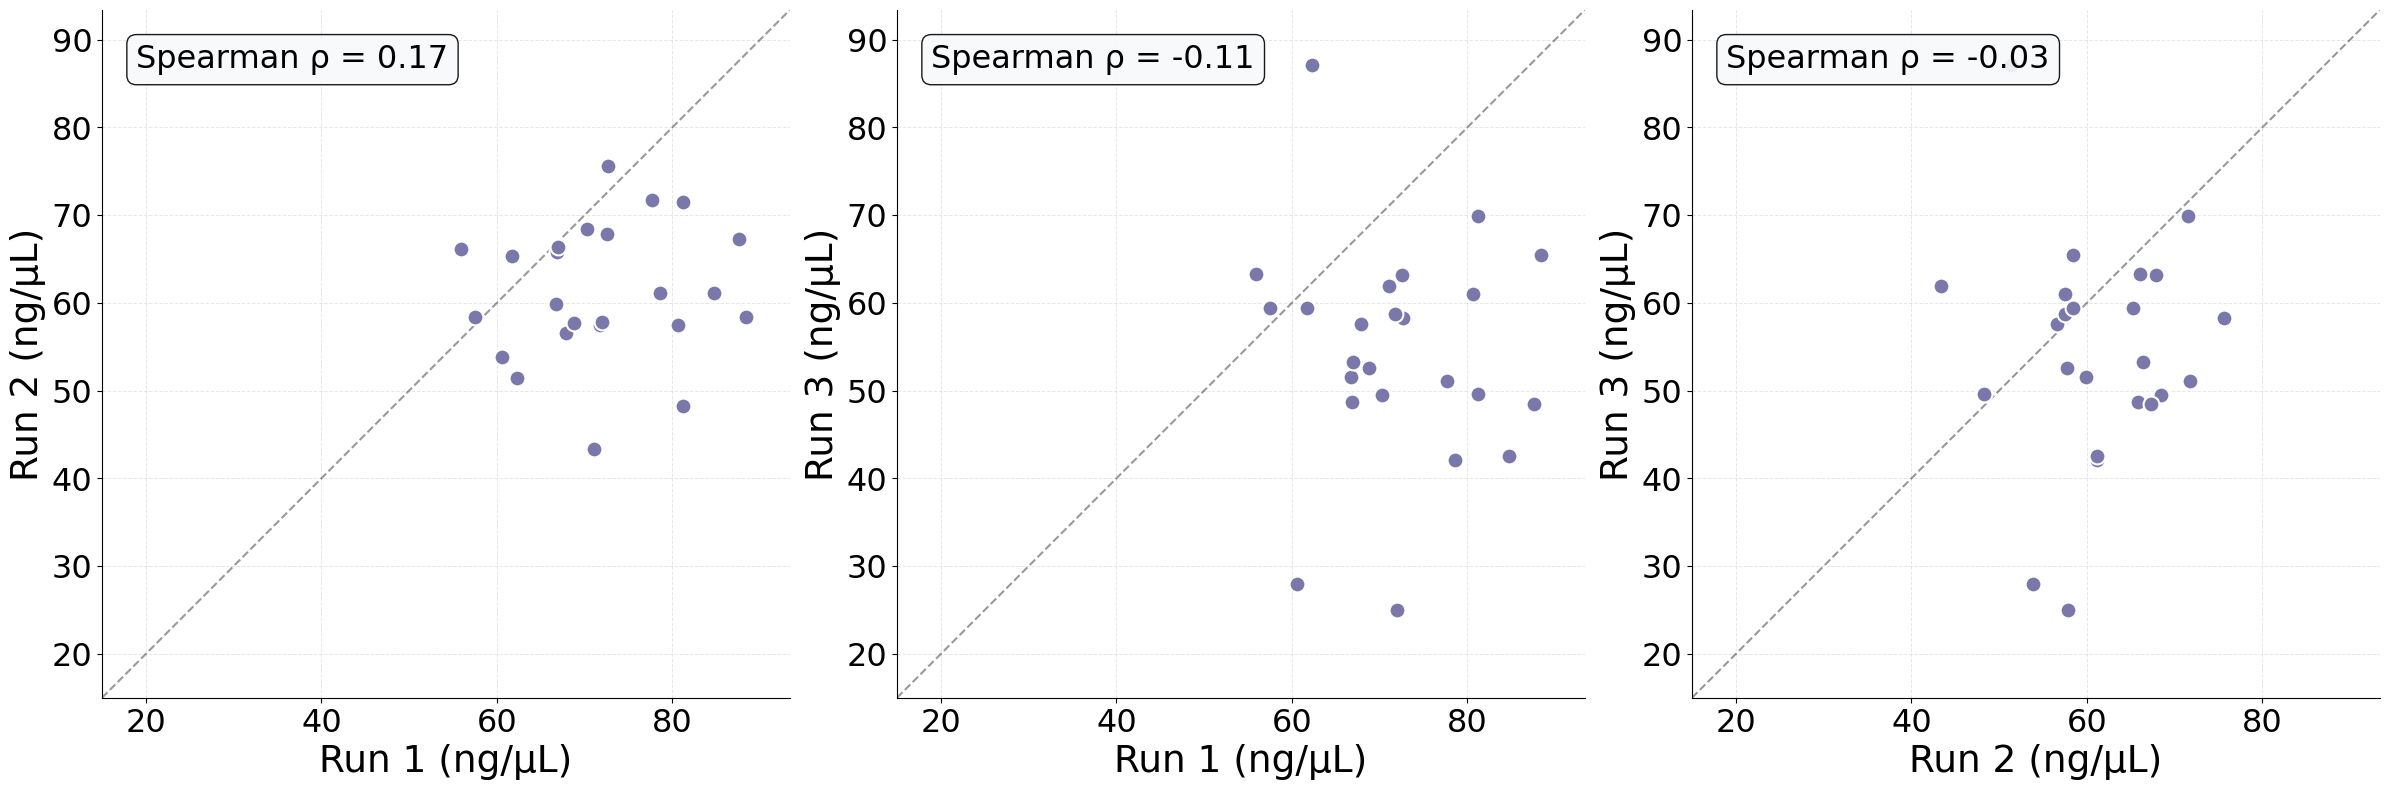

In [13]:
# E. Run vs run: if some ports were reliably good or bad, these would correlate
pairs = [(a, b) for i, a in enumerate(RUNS) for b in RUNS[i + 1:]]
lim = (np.floor(ot.values.min() / 10) * 10 - 5, ot.values.max() + 5)

fig, axes = plt.subplots(1, len(pairs), figsize=(8 * len(pairs), 8))
for ax, (a, b) in zip(axes, pairs):
    ax.scatter(ot[a], ot[b], s=130, color=color_opentrons, edgecolor='white', linewidth=1.5, zorder=3)
    ax.plot(lim, lim, 'k--', linewidth=1.5, alpha=0.4)
    rho = spearman[f'{a} vs {b}']
    # p value statistics go in the figure legend (reviewer request); values are printed by the analysis cells (section 3)
    ax.text(0.05, 0.95, f'Spearman ρ = {rho.statistic:.2f}', transform=ax.transAxes,
            fontsize=23, va='top', bbox=dict(boxstyle='round', facecolor='#f8f9fa', alpha=0.9))
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel(f'Run {a} (ng/μL)', fontsize=27)
    ax.set_ylabel(f'Run {b} (ng/μL)', fontsize=27)
    ax.tick_params(axis='both', labelsize=23)
    ax.grid(alpha=0.3, linestyle='--', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'C4J_RunVsRun.svg', dpi=1000, bbox_inches='tight')
plt.show()

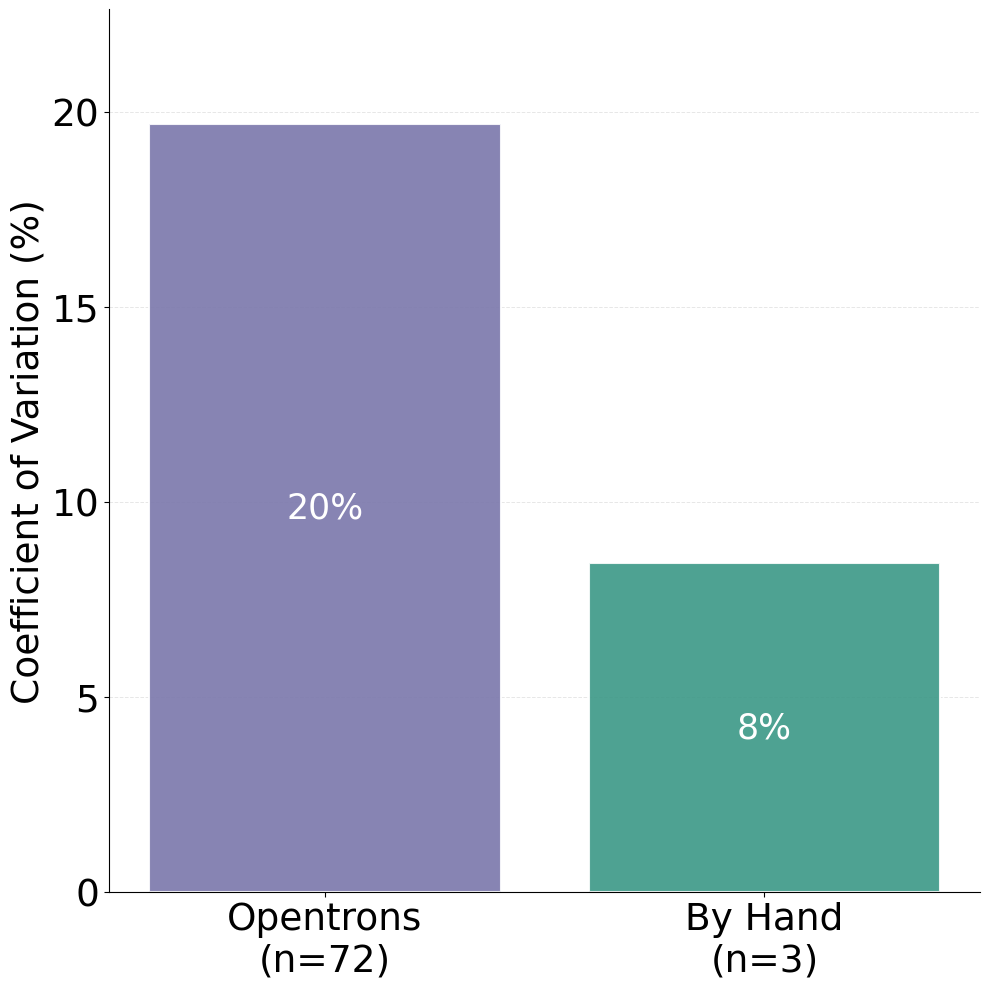

 Opentrons: CV 19.7% (95% CI 16.9-23.5), n = 72
   By Hand: CV 8.4% (95% CI 4.4-52.9), n = 3
F test of log-yield variance, Opentrons vs by hand: F = 7.20, p = 0.259
For reference, Opentrons mean within-run CV (run drift removed): 16.3%


In [14]:
# G. CV comparison between methods: by hand (n = 3) vs every Opentrons prep (n = 72).
# The Opentrons CV includes the run-to-run drift, since that is part of using the method.
# CIs use the chi-square interval for the SD (normal data), divided by the group mean, so the
# same method applies to n = 3 and n = 72. The test is an F test on the log-yield variance (the
# same variance-ratio approach as GeometricCV_Overall in miniprep.ipynb).
def cv_ci(x, level=0.95):
    n, a = len(x), (1 - level) / 2
    sd, mean = np.std(x, ddof=1), np.mean(x)
    lo = sd * np.sqrt((n - 1) / stats.chi2.ppf(1 - a, n - 1))
    hi = sd * np.sqrt((n - 1) / stats.chi2.ppf(a, n - 1))
    return 100 * lo / mean, 100 * hi / mean


ot_all = ot.values.ravel()
f_cv = np.var(np.log(ot_all), ddof=1) / np.var(np.log(hand), ddof=1)
d1, d2 = len(ot_all) - 1, len(hand) - 1
p_cv = min(1.0, 2 * min(stats.f.sf(f_cv, d1, d2), stats.f.cdf(f_cv, d1, d2)))

cv_table = pd.DataFrame([
    {'Method': 'Opentrons', 'n': len(ot_all), 'CV (%)': cv(ot_all), 'CI': cv_ci(ot_all), 'color': color_opentrons},
    {'Method': 'By Hand', 'n': len(hand), 'CV (%)': cv(hand.values), 'CI': cv_ci(hand.values), 'color': color_byhand},
])
ci_low = cv_table['CI'].str[0]
ci_high = cv_table['CI'].str[1]

def plot_cv_comparison(ax):
    x = np.arange(len(cv_table))
    # No error bars on the plot; the 95% CIs are printed below for the legend
    ax.bar(x, cv_table['CV (%)'], color=cv_table['color'], alpha=0.9, edgecolor='white', linewidth=1.5)
    for i, row in cv_table.iterrows():
        ax.text(i, row['CV (%)'] / 2, f"{row['CV (%)']:.0f}%", ha='center', va='center', fontsize=25,
                color='white')

    # F-test p value statistics go in the figure legend (reviewer request); values are printed by the analysis cells (below)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{m}\n(n={n})" for m, n in zip(cv_table['Method'], cv_table['n'])], fontsize=27)
    ax.set_ylabel('Coefficient of Variation (%)', fontsize=27)
    ax.tick_params(axis='y', labelsize=27)
    ax.set_ylim(0, cv_table['CV (%)'].max() * 1.15)
    style(ax)


fig, ax = plt.subplots(figsize=(10, 10))
plot_cv_comparison(ax)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'C4J_CoefficientOfVariation.svg', dpi=1000, bbox_inches='tight')
plt.show()

for _, row in cv_table.iterrows():
    print(f"{row['Method']:>10}: CV {row['CV (%)']:.1f}% (95% CI {row['CI'][0]:.1f}-{row['CI'][1]:.1f}), n = {row['n']}")
print(f"F test of log-yield variance, Opentrons vs by hand: F = {f_cv:.2f}, {fmt_p(p_cv)}")
print(f"For reference, Opentrons mean within-run CV (run drift removed): {within_run_cv:.1f}%")

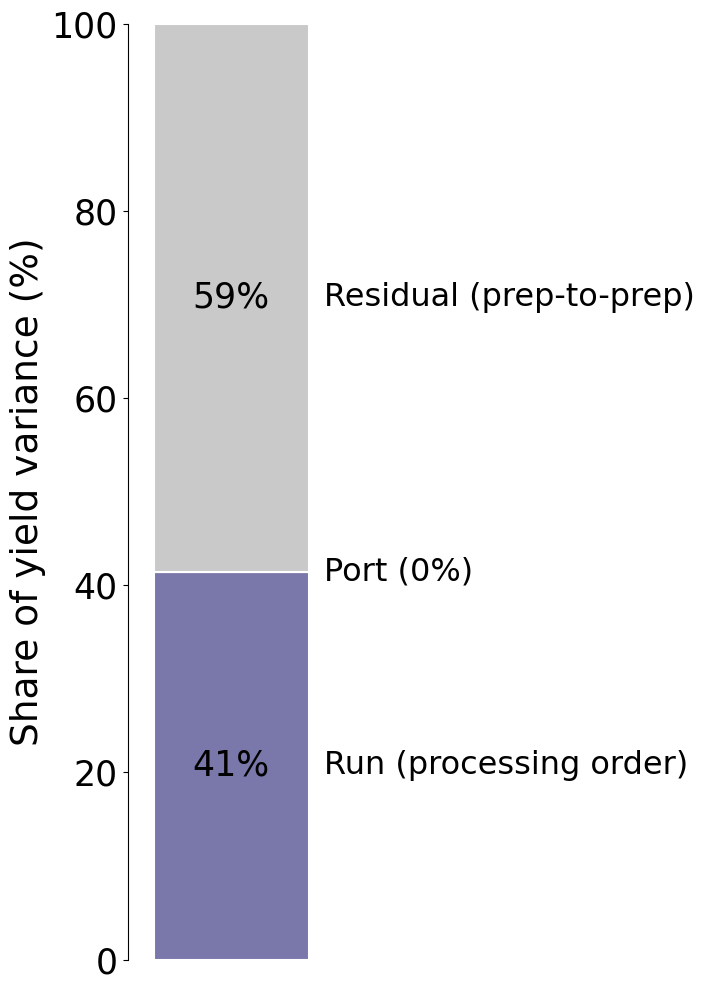

In [15]:
# F. Variance components: share of Opentrons yield variance from run, port and prep-to-prep noise
component_colors = [apc.palettes.primary[4], apc.palettes.primary[1], '#C9C9C9']


def plot_variance_components(ax):
    bottom = 0
    for (name, share), color in zip(var_share.items(), component_colors):
        ax.bar(0, share, bottom=bottom, color=color, edgecolor='white', linewidth=1.5, width=0.6)
        if share > 2:
            ax.text(0, bottom + share / 2, f'{share:.0f}%', ha='center', va='center', fontsize=25)
        ax.text(0.36, bottom + share / 2, name if share > 2 else f'{name} ({share:.0f}%)', ha='left', va='center', fontsize=23)
        bottom += share

    ax.set_xlim(-0.4, 1.6)
    ax.set_ylim(0, 100)
    ax.set_xticks([])
    ax.set_ylabel('Share of yield variance (%)', fontsize=27)
    ax.tick_params(axis='y', labelsize=25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)


fig, ax = plt.subplots(figsize=(7, 10))
plot_variance_components(ax)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'C4J_VarianceComponents.svg', dpi=1000, bbox_inches='tight')
plt.show()

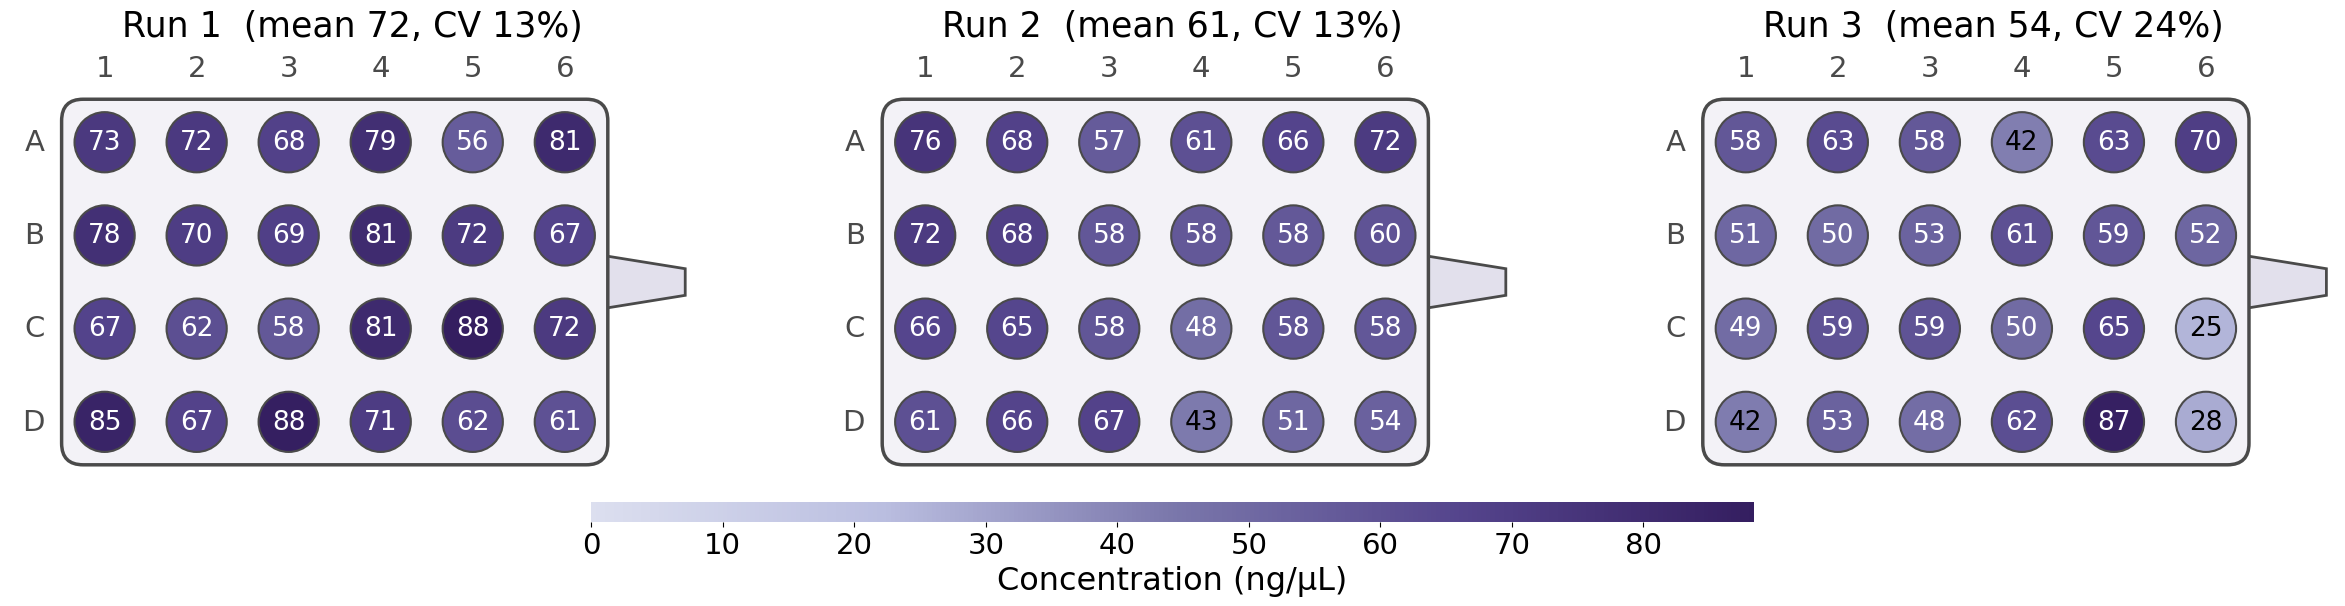

In [16]:
# Supplementary: manifold map for each run on a shared colour scale
fig, axes = plt.subplots(1, len(RUNS), figsize=(10 * len(RUNS), 8))
for ax, r in zip(axes, RUNS):
    sm = draw_manifold(ax, ot[r], vmin=0, vmax=ot.values.max(), fontsize=19)
    ax.set_title(f'Run {r}  (mean {ot[r].mean():.0f}, CV {cv(ot[r]):.0f}%)', fontsize=25, pad=4)
cbar = fig.colorbar(sm, ax=axes, orientation='horizontal', pad=0.04, aspect=60, shrink=0.5)
cbar.set_label('Concentration (ng/μL)', fontsize=23)
cbar.ax.tick_params(labelsize=21)
cbar.outline.set_visible(False)
plt.savefig(PLOT_DIR / 'C4J_ManifoldMapPerRun.svg', dpi=1000, bbox_inches='tight')
plt.show()

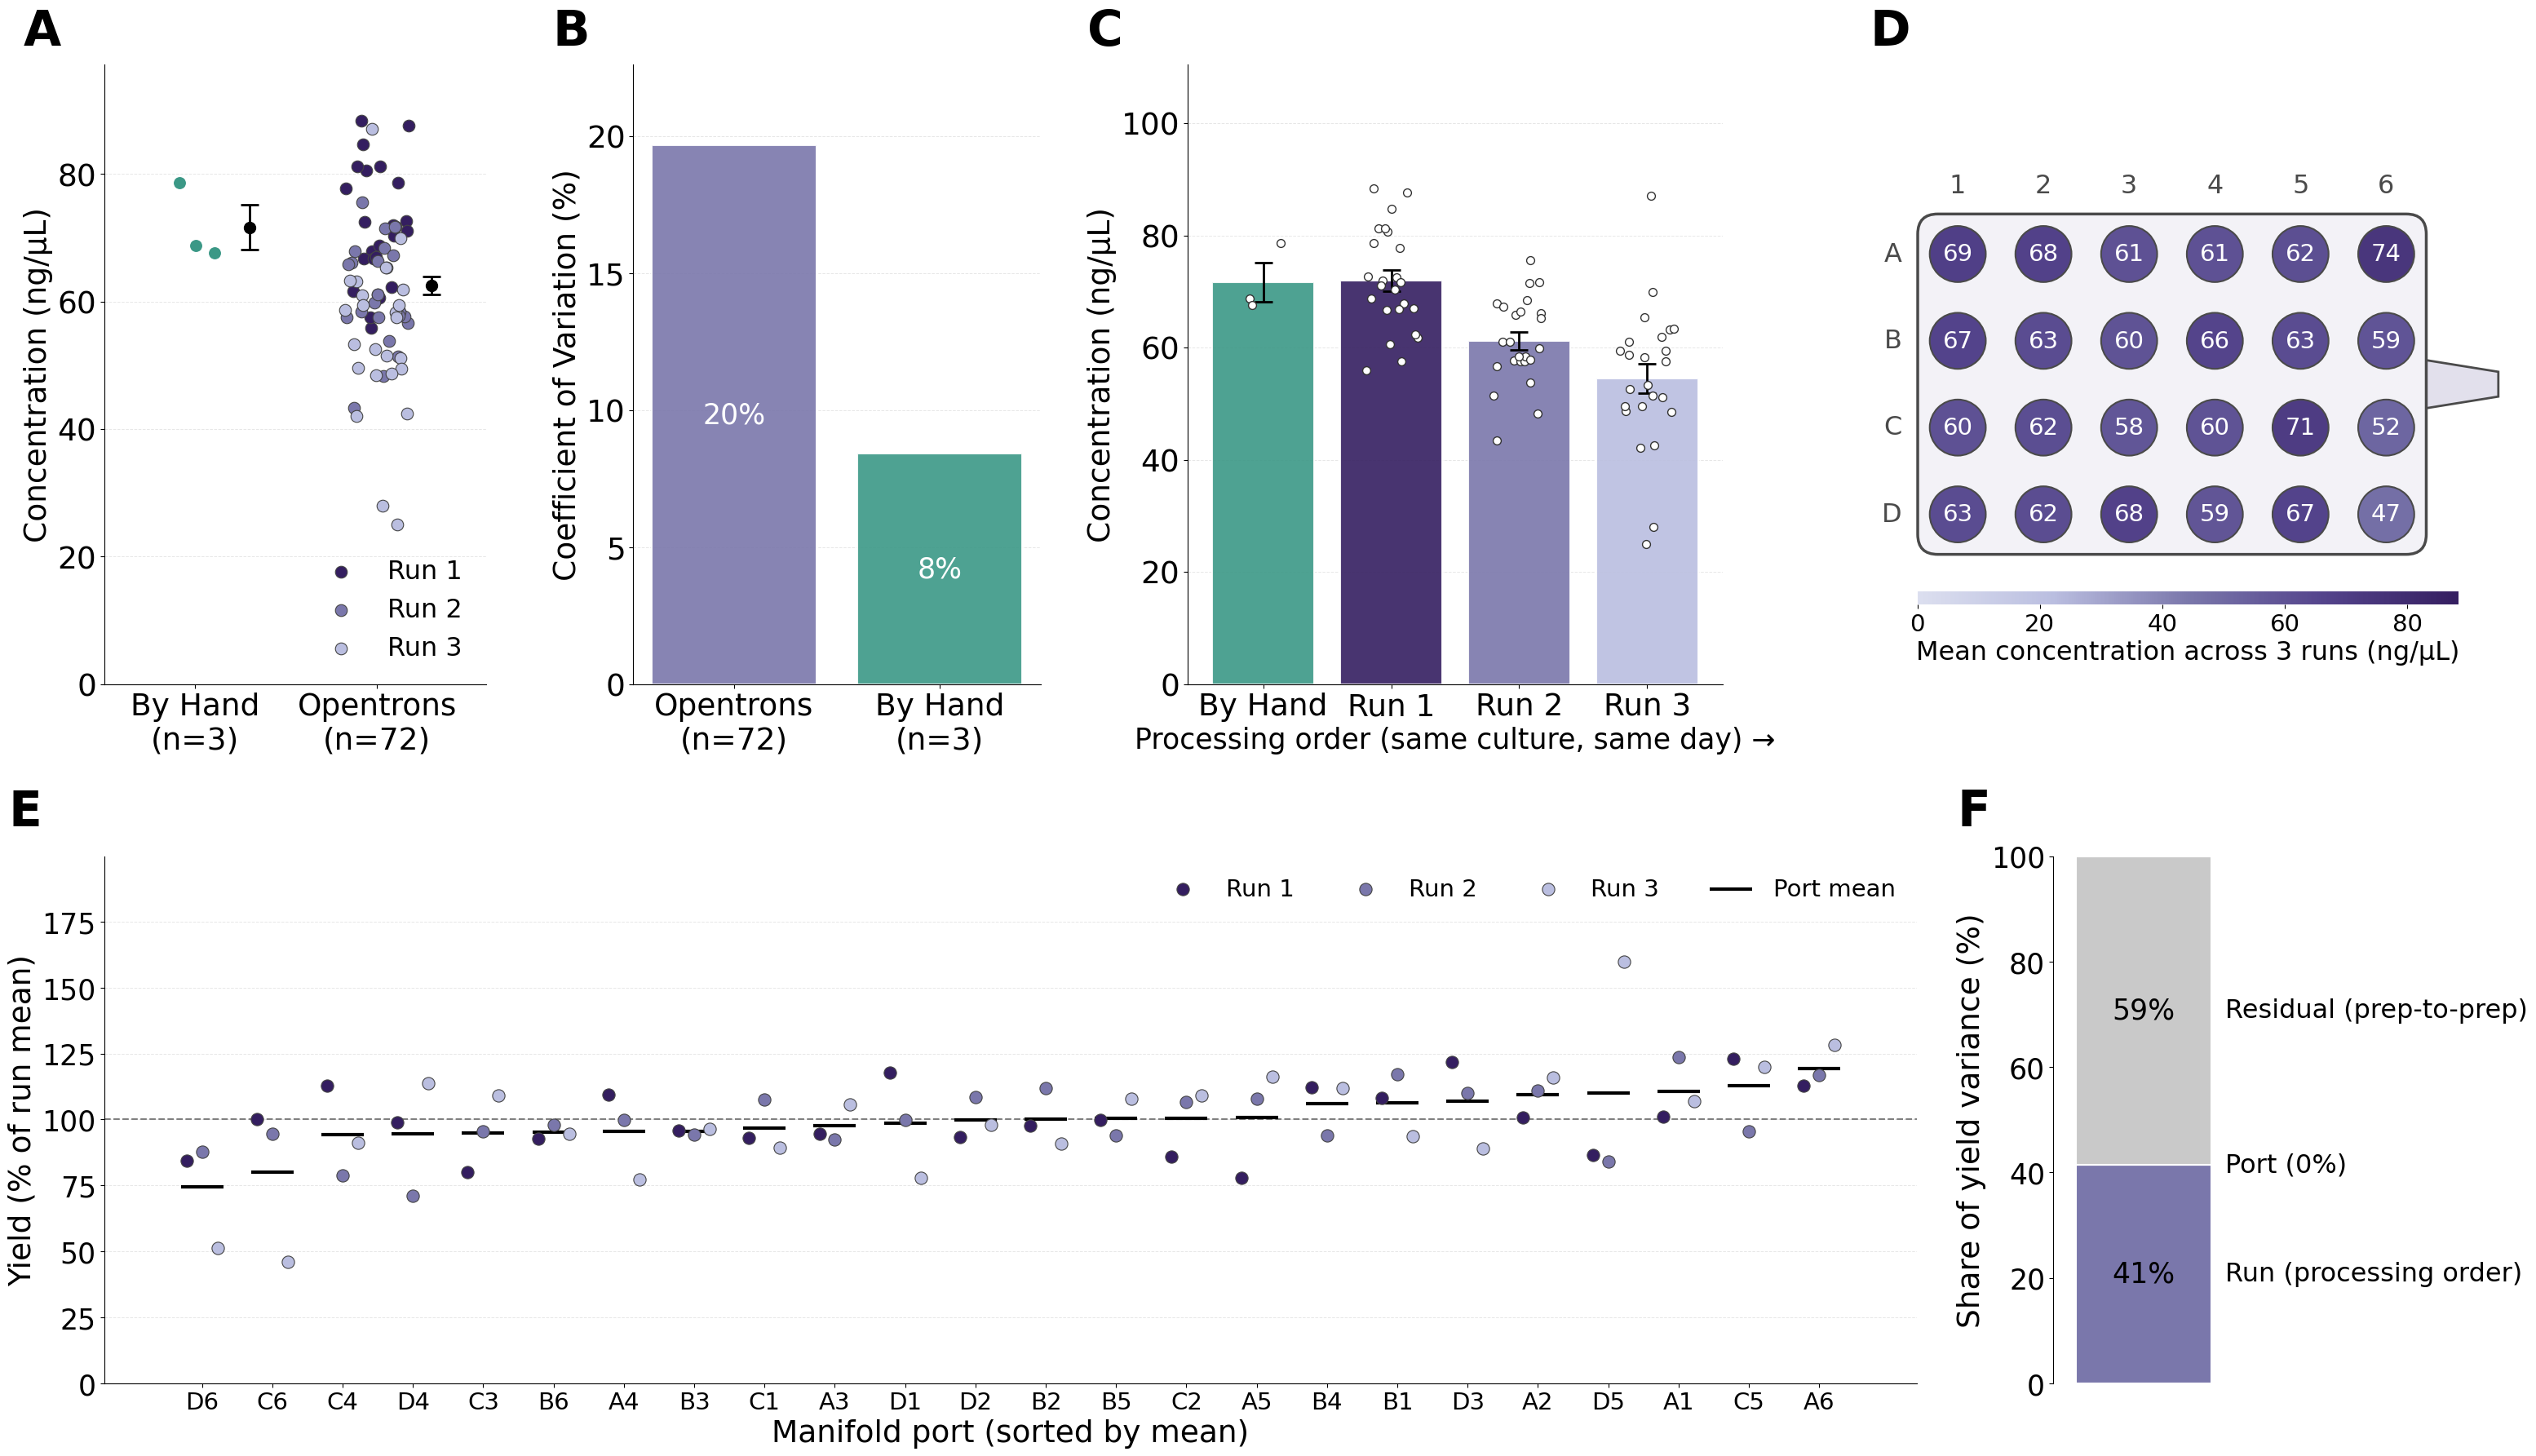

In [17]:
# Combined figure for the paper: A yield by method, B CV by method (the controlled variability
# comparison), C processing order, D manifold map, E port consistency, F variance components.
# Panels are drawn by the same functions as the standalone SVGs above.
fig = plt.figure(figsize=(38, 21))
grid = fig.add_gridspec(2, 1, height_ratios=[1, 0.85], hspace=0.3)
top_row = grid[0].subgridspec(1, 4, width_ratios=[0.75, 0.8, 1.05, 1.25], wspace=0.3)
panels = [
    (fig.add_subplot(top_row[0, 0]), plot_yield_by_method),
    (fig.add_subplot(top_row[0, 1]), plot_cv_comparison),
    (fig.add_subplot(top_row[0, 2]), plot_processing_order),
    (fig.add_subplot(top_row[0, 3]), plot_manifold_map),
]
# Bottom row: port consistency takes most of the width, variance components sit to its right
bottom_row = grid[1].subgridspec(1, 2, width_ratios=[0.8, 0.2], wspace=0.12)
panels += [
    (fig.add_subplot(bottom_row[0, 0]), plot_port_consistency),
    (fig.add_subplot(bottom_row[0, 1]), plot_variance_components),
]
for ax, draw in panels:
    draw(ax)

# Letters sit at the left of each panel's full extent (including axis labels) and share one
# height per row, so D lines up with A-C even though the manifold panel is shrunk to scale
renderer = fig.canvas.get_renderer()
bboxes = [ax.get_tightbbox(renderer).transformed(fig.transFigure.inverted()) for ax, _ in panels]
row_of = [0, 0, 0, 0, 1, 1]
row_top = {row: max(b.y1 for b, r in zip(bboxes, row_of) if r == row) for row in set(row_of)}
for letter, bbox, row in zip('ABCDEF', bboxes, row_of):
    fig.text(bbox.x0, row_top[row] + 0.005, letter, fontsize=43, fontweight='bold', ha='left', va='bottom')

plt.savefig(PLOT_DIR / 'C4J_Combined.svg', dpi=1000, bbox_inches='tight')
# Raster copy for submission systems and slides
plt.savefig(PLOT_DIR / 'C4J_Combined.png', dpi=600, bbox_inches='tight', facecolor='white')
plt.show()

## Summary for the revision

- **No port effect.** Two-way ANOVA port x run: F = 0.97, p = 0.52 (Friedman p = 0.43). No row, column
  or edge-vs-centre effect, and port rankings do not carry over between runs (Spearman -0.11 to 0.17).
  The lowest port, D6, is within what chance produces for the worst of 24 (permutation p = 0.16).
  Variance attributable to port: 0%. Answers R1's single-plasmid, all-ports request.
- **Variability is processing order plus prep-to-prep noise, not the manifold.** Run explains ~41% of
  yield variance and residual prep-to-prep noise ~59%. Yield falls ~8.7 ng/uL (~12%) per sequential run
  from the same lysate (p < 0.001), so the time the lysate waits before purification is the measurable
  cause of the extra spread (R7).
- **Matched comparison with hand preps (R5).** On the same culture, run 1 (processed straight after the
  hand preps) matches the by-hand yield (71.9 vs 71.7 ng/uL, Welch p = 0.96). Runs 2 and 3 are 85% and
  76% of the hand yield. Within-run CV is 13-24% (mean 16%) vs 8% by hand (n = 3, so the hand estimate
  is imprecise); far below the 58% vs 19% reported in the submitted manuscript from mixed plasmids and cultures.
- Run 3's higher CV is largely two low preps (C6, D6); without them it drops from 23.5% to 17.4%.